# Project 3: Time Series Modeling of Air Quality in Nairobi

- **Concepts**:
    - Time-Series Analysis, NoSQL (MongoDB), Lagged Regression, AR & ARMA Models.
- **Description**: 
    - This project deals with time-indexed data. Using air quality measurements from Nairobi stored in MongoDB, we query, prepare, and forecast time series data. The project builds from simple lagged regression up to Autoregressive (AR) and ARMA models

## 1.0 Prepare  

In [1]:
# import liberaries
import warnings
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px 
import pytz
from statsmodels.graphics.tsaplots import plot_acf , plot_pacf
from pymongo.mongo_client import MongoClient
from sklearn.metrics import mean_absolute_error
from statsmodels.tsa.ar_model import AutoReg
from statsmodels.tsa.seasonal import seasonal_decompose


warnings.simplefilter(action="ignore", category=FutureWarning)



### Data Wrangling with MongoDB 

1. Connect to the local Docker container 

In [21]:
import pandas as pd
from pymongo import MongoClient

# 1. Connect to your database
client = MongoClient("mongodb://localhost:27017/")
db = client["air-quality"]
nairobi_collection = db["nairobi"]

# 2. Define the adapted wrangle function
def wrangle(collection, location=3981, year="2025"):
    """
    Wrangles PM2.5 data from MongoDB.
    """
    # Use $regex to match the string timestamp starting with "2025"
    query = {
        "timestamp": {"$regex": f"^{year}"}, 
        "location": location, 
        "value_type": "P2"
    }
    
    # Pull only value and timestamp fields
    result = collection.find(
        query,
        projection={'value': 1, 'timestamp': 1, '_id': 0}
    )
    
    # Import into DataFrame
    df = pd.DataFrame(list(result))
    
    # Return empty series if no data matches the query
    if df.empty:
        return pd.Series(dtype='float64')
    
    # Convert string timestamps to actual pandas datetime objects
    df['timestamp'] = pd.to_datetime(df['timestamp'])
    
    # Set the datetime column as the index
    df.set_index('timestamp', inplace=True)
    
    # Convert timezone from UTC (+00:00) to Nairobi
    df.index = df.index.tz_convert('Africa/Nairobi')
    
    # Convert the 'value' column to float (forces any weird strings to NaN)
    df["value"] = pd.to_numeric(df["value"], errors='coerce')
    
    # Remove outliers (readings >= 250)
    # We assign valid values to a new "P2" column
    df["P2"] = df.loc[df["value"] < 250, "value"]
    df.drop(columns="value", inplace=True)
    
    # Resample to 1-Hour intervals (taking the mean) and forward-fill missing hours
    # The 'ffill' method replaces the old 'fillna(method="ffill")' which is deprecated
    y = df['P2'].resample('1h').mean().ffill()
    
    # Drop any remaining nulls (e.g., if the very first row was null)
    y.dropna(inplace=True)
    
    return y

# 3. Execute the function
y = wrangle(nairobi_collection)
print(y.head())

timestamp
2025-08-01 03:00:00+03:00    24.016000
2025-08-01 04:00:00+03:00    27.375000
2025-08-01 05:00:00+03:00    32.050000
2025-08-01 06:00:00+03:00    48.875714
2025-08-01 07:00:00+03:00    41.044000
Freq: h, Name: P2, dtype: float64


## 2.0 Exploratory Data Analysis (EDA) 

- When dealing with AR Models, we use AACF and PACF plots to plot the data in y for us to better understand auto correlation.

### Data Distribution 

- A boxplot of the PM2.5 readings reveals the central tendency and spread of the data. This visualization was also instrumental in identifying the presence of extreme outliers, which we handled in the wrangling phase.

<Axes: title={'center': 'Distribution of PM2.5 Readings'}>

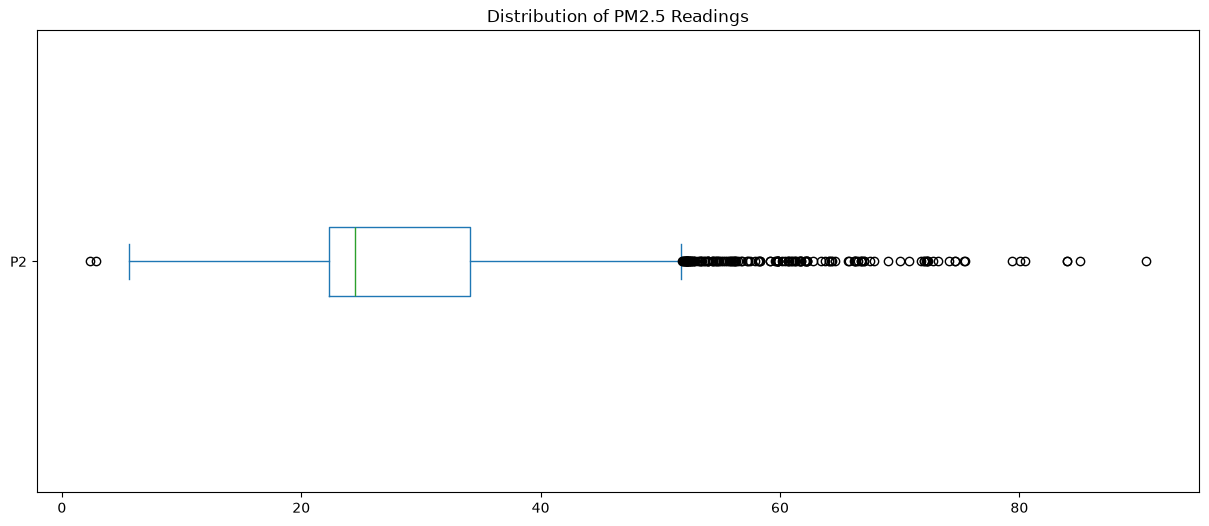

In [24]:
fig, ax = plt.subplots(figsize=(15, 6))
df = pd.DataFrame(y)
df['P2'].plot(kind='box' ,vert=False,title='Distribution of PM2.5 Readings')

### Time Series Visualization

- Plotting the PM2.5 readings over time - t showcase the data's behavior, such as daily patterns or long-term trends.

<Axes: title={'center': 'PM2.5 Time Series'}, xlabel='Time', ylabel='PM2.5'>

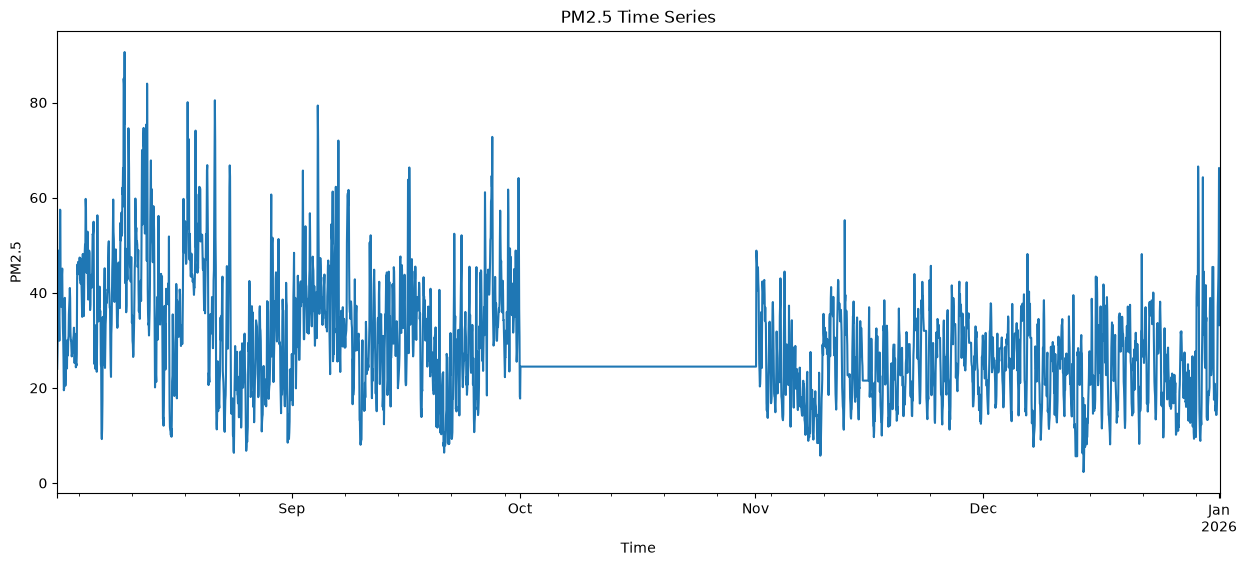

In [25]:
fig, ax = plt.subplots(figsize=(15, 6))
y.plot(xlabel='Time', ylabel='PM2.5', title="PM2.5 Time Series",ax=ax)

### Autocorrelation Analysis

- Time-series data often exhibits autocorrelation, where an observation at one point in time is correlated with observations at previous points. We use Autocorrelation Function (ACF) and Partial Autocorrelation Function (PACF) plots to analyze these relationships.
    - ACF Plot: Shows the correlation of the time series with its own lagged values. The slow decay in our ACF plot suggests a strong autoregressive component.
    - PACF Plot: Shows the correlation between an observation and its lagged values after removing the effects of the intervening lags. The sharp drop-off in the PACF plot helps in determining the order of the autoregressive (AR) part of our model.


#### ACF Plot

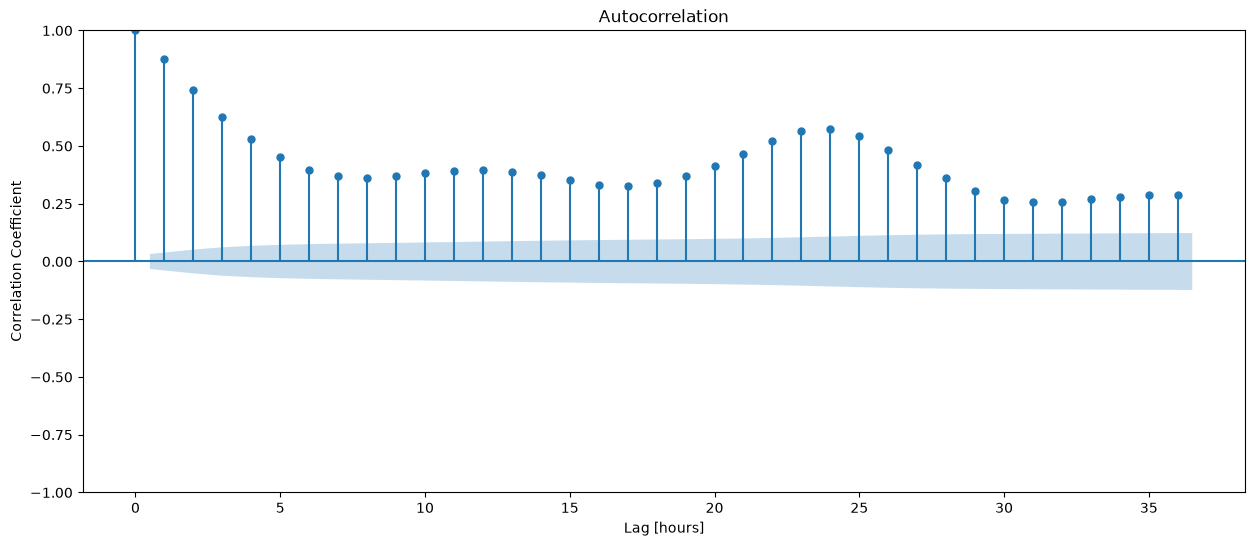

In [ ]:
fig, ax = plt.subplots(figsize=(15, 6))
plot_acf(y, ax=ax)
plt.xlabel("Lag [hours]")
plt.ylabel("Correlation Coefficient");


- ACF shows a strong auto correlation. 


#### PACF Plot

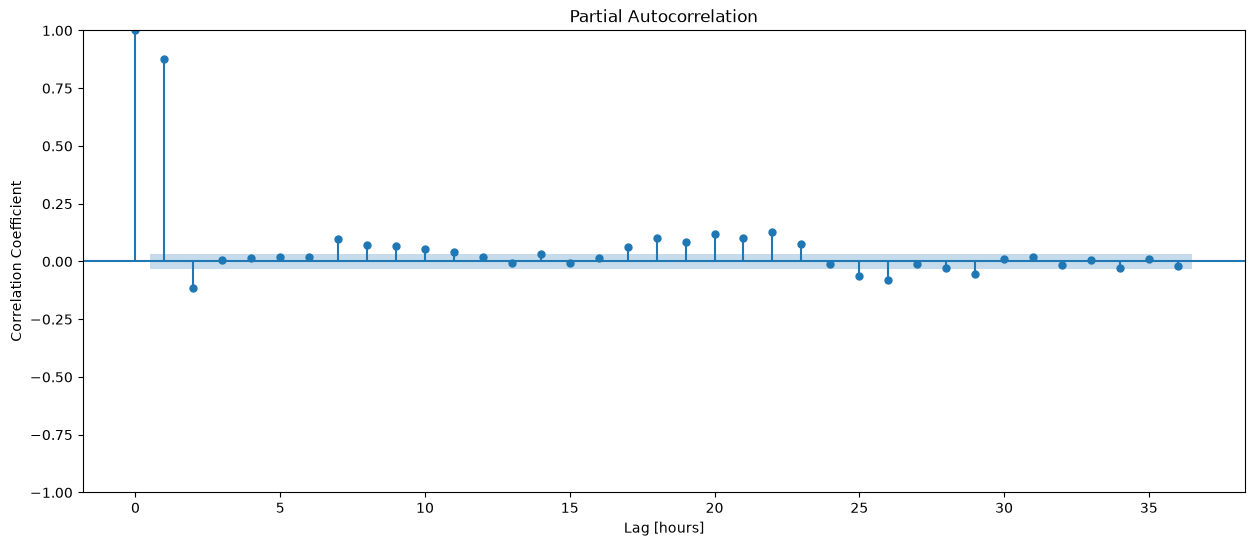

In [23]:
fig, ax = plt.subplots(figsize=(15, 6))
plot_pacf(y, ax=ax)
plt.xlabel("Lag [hours]")
plt.ylabel("Correlation Coefficient");

#### Split 

- For our final modeling phase, we define a specific training and testing period. The model will be trained on data from October 2018 and tested on its ability to forecast for the first day of November 2018. This chronological split is essential for validating a time-series model's out-of-sample performance.


In [ ]:
y_train = y.loc['10-2018']
y_test = y.loc['11-01-2018']



#### Baseline Model

- A baseline model provides a benchmark against which we can measure the performance of our more sophisticated models. A common and effective baseline for time-series forecasting is the persistence model, where the prediction for the next time step is simply the value of the current time step. We calculate the MAE for this naive forecast.

In [ ]:
y_train_mean = y_train.mean()
y_pred_baseline = [y_train_mean]* len(y_train)
mae_baseline = mean_absolute_error(y_train , y_pred_baseline)
print("Mean P2 Reading:", round(y_train_mean, 2))
print("Baseline MAE:", round(mae_baseline, 2))

## 4.0 Modelling  


- Our modeling strategy is iterative. We begin with a simple baseline and progressively build more complex models, evaluating each for its predictive accuracy. The primary evaluation metric is the Mean Absolute Error (MAE), which measures the average magnitude of the errors in a set of predictions, without considering their direction.

### 4.1 Model 1: Simple Linear Regression

- Our first model uses a simple linear regression approach. The key feature is the PM2.5 value from the previous hour (P2.L1). The hypothesis is that the current air quality is strongly dependent on the air quality of the recent past. While overly simplistic for complex time-series dynamics, it serves as a better-than-naive baseline.

In [ ]:
df = y.to_frame()
df['P2.L1'] = df['P2'].shift(1)
df.dropna(inplace=True)

cutoff = int(len(df) * 0.8)

X_train = df.iloc[:cutoff].drop(columns='P2')
y_train_lr = df.iloc[:cutoff]['P2']
X_test = df.iloc[cutoff:].drop(columns='P2')
y_test_lr = df.iloc[cutoff:]['P2']

In [ ]:
model_lr = LinearRegression()
model_lr.fit(X_train, y_train_lr)

training_mae_lr = mean_absolute_error(y_train_lr, model_lr.predict(X_train))
test_mae_lr = mean_absolute_error(y_test_lr, model_lr.predict(X_test))

print("Linear Regression Training MAE:", round(training_mae_lr, 2))
print("Linear Regression Test MAE:", round(test_mae_lr, 2))



### 4.2. Model 2: Autoregressive (AR) Model 
- An Autoregressive (AR) model is a more formal time-series model that regresses a value on its own past values. The order of the AR model, p, determines how many previous (lagged) time steps are included. Based on our PACF plot, which showed significant correlations up to approximately 24-26 hours, we select p=26 for this model.

In [ ]:
model_ar = AutoReg(y_train, lags=26).fit()
y_pred_ar = model_ar.predict().dropna()
training_mae_ar = mean_absolute_error(y_train.iloc[26:], y_pred_ar)
print("AR Model Training MAE:", training_mae_ar)

### 4.3. Model 3: ARMA Model with Hyperparameter Tuning 

- The Autoregressive Moving Average (ARMA) model is an even more powerful tool. It combines two components:
    - Autoregressive (AR) part (p): Models the relationship between an observation and a number of lagged observations.
    - Moving Average (MA) part (q): Models the relationship between an observation and the residual error from a moving average model applied to lagged observations.
- Finding the optimal values for the hyperparameters p and q is critical for model performance. We conduct a grid search, systematically training and evaluating ARMA models with various combinations of p and q to find the combination that yields the lowest training MAE.

In [ ]:
p_params = range(0,25,8)
q_params = range(0,3,1)

In [ ]:
# Create dictionary to store MAEs
mae_grid = dict()
# Outer loop: Iterate through possible values for `p`
for p in p_params:
    # Create key-value pair in dict. Key is `p`, value is empty list.
    mae_grid[p] = list()
    # Inner loop: Iterate through possible values for `q`
    for q in q_params:
        # Combination of hyperparameters for model
        order = (p, 0, q)
        # Note start time
        start_time = time.time()
        # Train model
        model = ARIMA(y_train,order=order).fit()
        # Calculate model training time
        elapsed_time = round(time.time() - start_time, 2)
        print(f"Trained ARIMA {order} in {elapsed_time} seconds.")
        # Generate in-sample (training) predictions
        y_pred = model.predict()
        # Calculate training MAE
        mae = mean_absolute_error(y_train,y_pred)
        # Append MAE to list in dictionary
        mae_grid[p].append(mae)

print()
print(mae_grid)

- The results of our grid search are best visualized using a heatmap. This allows us to quickly identify the (p, q) combination that minimizes the MAE. Based on the heatmap, we select the optimal hyperparameters for our final model, balancing performance with computational efficiency.


In [ ]:
mae_df = pd.DataFrame(mae_grid)
mae_df.round(4)

In [ ]:


sns.heatmap(mae_df,cmap='Blues')
plt.xlabel("p Values")
plt.ylabel("q Values")
plt.title("ARMA Grid Search (Criterion MAE)");



## 5.0 Final Model Evaluation

- Based on the grid search, an ARMA(8,1) model appears to offer a good balance of accuracy and computational cost. We proceed with this model for our final evaluation.


### Residual Analysis
- Before final evaluation, we examine the model's residuals (the differences between predicted and actual values). An ideal model will have residuals that are randomly distributed around zero, with no discernible patterns. The diagnostic plots for our chosen ARMA(8,1) model confirm that the residuals approximate white noise, indicating a good model fit.


In [ ]:
final_model = ARIMA(y_train, order=(8, 0, 1)).fit()
fig, ax = plt.subplots(figsize=(15, 12))
final_model.plot_diagnostics(fig=fig);

### Walk-Forward Validation
- The most rigorous method for evaluating a time-series model is walk-forward validation (WFV). In this process, the model makes a one-step-ahead forecast, then the actual observation for that step is added to the training data, and the model is re-trained before making the next forecast. This simulates a real-world scenario where the model continuously learns as new data becomes available. We perform WFV on our entire test set.

In [ ]:


# Walk-forward validation for ARMA(8,1)
preds = []
history = y_train.copy()
for i in range(len(y_test)):
    model = ARIMA(history, order=(8, 0, 1)).fit()
    next_pred = model.forecast()
    preds.append(next_pred.iloc[0])
    # Append the actual observed value to history for next step
    history = pd.concat([history, pd.Series(y_test.iloc[i], index=[y_test.index[i]])])

# Create a Series with the same index as y_test
y_pred_wfv = pd.Series(preds, index=y_test.index)



### Key Findings & Results
- The walk-forward validation provides the most realistic estimate of the model's performance on unseen data. Our final ARMA(8,1) model achieves a significantly lower Mean Absolute Error than the baseline, demonstrating its effectiveness.


In [ ]:
test_mae = mean_absolute_error(y_test, y_pred_wfv)
print("Test MAE (Walk-Forward Validation):", round(test_mae, 2))

- To visualize the model's performance, we plot its predictions against the actual PM2.5 values for the test period. The plot shows that our model's predictions closely track the true values, capturing the fluctuations in air quality with high fidelity.


In [ ]:
df_predictions = pd.DataFrame(
    {"y_test":y_test , 'y_pred_wfv': y_pred_wfv}
)

fig = px.line(df_predictions, labels={"value": "PM2.5", "timestamp": "Time"})
fig.update_layout(title_text="Nairobi PM2.5 Forecast vs. Actuals", yaxis_title="PM2.5")
fig.show()


## Business Implications & Recommendations

- The successful development of this ARMA model has direct and valuable implications:
    - Public Health: The model can serve as the engine for a public health alert system. By accurately forecasting PM2.5 levels an hour in advance, authorities can issue warnings to the public, especially vulnerable populations, allowing them to take protective measures like staying indoors or wearing masks.
    - Environmental Policy: Consistent, accurate air quality data and forecasts can help policymakers understand pollution patterns, identify sources, and evaluate the effectiveness of environmental interventions.
    - Scalability: The methodology developed in this project is scalable and can be applied to data from other sensors across Nairobi or in other cities, creating a comprehensive air quality monitoring and forecasting network.
- Recommendation: We recommend the deployment of the ARMA(8,1) model into a production environment to provide real-time hourly forecasts for PM2.5 levels at the sensor location.
Future Work & Next Steps
- While the current model is robust, there are several avenues for future improvement:
    - Multivariate Models: Incorporate other relevant variables, such as weather data (temperature, humidity, wind speed) or traffic data, by using more advanced models like SARIMAX or vector autoregression (VAR).
    - Advanced Architectures: Explore machine learning and deep learning models, such as LSTMs (Long Short-Term Memory networks), which are specifically designed for sequence prediction and may capture more complex, non-linear patterns.
    - Expanded Geographic Scope: Apply the modeling process to other sensor sites to build a city-wide forecasting system.

## Conclusion
- This project successfully demonstrates the power of time-series analysis in addressing a critical public health issue. By systematically progressing from data wrangling to advanced modeling and rigorous evaluation, we have developed a reliable ARMA model capable of forecasting hourly PM2.5 concentrations in Nairobi. The resulting tool not only achieves strong technical performance but also offers tangible value for public health and environmental management. The framework established here provides a solid foundation for future enhancements and broader application.
